# 03 · LEMIS vs CITES: what alignment has to bridge

Notebooks 01 and 02 describe each dataset on its own. This notebook puts them side by side, field by field, to **find** what a shared schema has to reconcile before LEMIS enforcement labels can be transferred to CITES records. It assumes no alignment rule: the code lists of both datasets are shown next to each other, and every mismatch is read off the data. The only things taken as given are the publishers' reading rules in [`DATA/USING_LEMIS_AND_CITES.md`](../../DATA/USING_LEMIS_AND_CITES.md), cited as *guide §x*, and the findings of notebooks 01 (L1–L13) and 02 (C1–C13).

The alignment rules that follow from these findings (X1–X12 at the end) are recorded in [`DATA/ALIGNING_LEMIS_AND_CITES.md`](../../DATA/ALIGNING_LEMIS_AND_CITES.md).

The current crosswalk in `wildguard/schema_alignment.py` is used only to measure **coverage**: which raw values it does and does not map. The aim is to inform report §3.4, not to validate the current code.

**Populations.** LEMIS: all 5,512,706 line items, 2000–2014, unless stated. CITES: animal records 2015–2024 without Appendix `N`. Shares of CITES use **exporter-reported records** unless stated, because mirror records would otherwise count the same trade twice (guide §2.2).

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

import eda_setup as E
from wildguard import schema_alignment as SA

E.style()
con = E.connect()


def Q(sql):
    return E.q(con, sql)


def pct(s):
    return (100 * s).round(2).astype(str) + "%"


con.execute("""
    CREATE VIEW win AS SELECT * FROM cites_window WHERE Appendix <> 'N';
    CREATE VIEW win_e AS SELECT * FROM win WHERE "Reporter.type" = 'E';
""")
# meaning of each LEMIS code, from the USFWS code list shipped with the data
codes = pd.read_csv(E.config.DATA_DIR / "reference" / "lemis_codes.csv", keep_default_na=False)
LEMIS_MEANING = {f: dict(zip(g.code, g.value)) for f, g in codes.groupby("field")}

N_L = Q("SELECT count(*) FROM lemis").iat[0, 0]
N_E = Q("SELECT count(*) FROM win_e").iat[0, 0]
print(f"LEMIS line items: {N_L:,}   CITES exporter-reported window records: {N_E:,}")

LEMIS line items: 5,512,706   CITES exporter-reported window records: 4,835,543


## 1. Side by side

In [2]:
lem = Q("""SELECT count(*) AS n, count(DISTINCT control_number) AS shipments, avg(label) AS rate,
                  count(DISTINCT genus) AS genera, count(DISTINCT class) AS classes FROM lemis""").iloc[0]
cit = Q("""SELECT count(*) AS n, count(*) FILTER (WHERE "Reporter.type" = 'E') AS e,
                  count(DISTINCT Genus) AS genera, count(DISTINCT Class) AS classes FROM win""").iloc[0]
pd.DataFrame({
    "LEMIS": ["product line item of a US import declaration", "2000-2014", f"{lem.n:,.0f}",
              "US (importer) only", "every declared wildlife import, CITES-listed or not",
              f"yes: {lem.rate:.2%} enforcement cases", "yes (USD, with gaps)",
              f"{lem.classes:.0f} / {lem.genera:,.0f}"],
    "CITES (window)": ["permit line item as reported by one Party", "2015-2024", f"{cit.n:,.0f}",
                       f"exporter and importer ({cit.e:,.0f} exporter-reported)",
                       "CITES-listed species only (Appendix N excluded)", "no", "no",
                       f"{cit.classes:.0f} / {cit.genera:,.0f}"],
}, index=["one row is", "years", "records", "reported by", "scope", "enforcement labels",
          "declared value", "classes / genera"])

,LEMIS,CITES (window)
one row is,product line item of a US import declaration,permit line item as reported by one Party
years,2000-2014,2015-2024
records,"5,512,706","8,240,582"
reported by,US (importer) only,"exporter and importer (4,835,543 exporter-repo..."
scope,"every declared wildlife import, CITES-listed o...",CITES-listed species only (Appendix N excluded)
enforcement labels,yes: 1.74% enforcement cases,no
declared value,"yes (USD, with gaps)",no
classes / genera,"63 / 6,506","17 / 1,226"


## 2. Coded fields: source and purpose

The test used throughout this notebook: **list every value of a shared field that occurs in one dataset but not the other**, with what each code means in each dataset. A code that appears on one side only, or a letter that means different things on the two sides, is something alignment must handle. Meanings come from the LEMIS code list (`DATA/reference/lemis_codes.csv`) and the CITES guide's annexes.

In [3]:
def compare(lsql, csql, field, labels):
    l = Q(f"SELECT {lsql} AS code, count(*) AS lemis FROM lemis GROUP BY 1")
    c = Q(f"SELECT {csql} AS code, count(*) AS cites_E FROM win_e GROUP BY 1")
    df = l.merge(c, on="code", how="outer").fillna({"lemis": 0, "cites_E": 0})
    df["code"] = df.code.fillna("(missing)")
    df.insert(1, "LEMIS meaning", df.code.map(LEMIS_MEANING[field]))
    df.insert(2, "CITES meaning", df.code.map(labels))
    df["lemis share"] = pct(df.lemis / df.lemis.sum())
    df["cites share"] = pct(df.cites_E / df.cites_E.sum())
    df["only in"] = df.apply(lambda r: "LEMIS" if r.cites_E == 0 else "CITES" if r.lemis == 0 else "",
                             axis=1)
    return df.sort_values("lemis", ascending=False).reset_index(drop=True)

compare("source", "Source", "source", E.CITES_SOURCE)

,code,LEMIS meaning,CITES meaning,lemis,cites_E,lemis share,cites share,only in
0,W,Specimens taken from the wild,wild,"4,301,115","2,924,055",78.02%,60.47%,
1,C,"Animals bred in captivity, parts and derivatives",bred in captivity,"811,618","1,194,468",14.72%,24.7%,
2,R,Specimens originating from a ranching operation,ranched,"229,471","265,211",4.16%,5.48%,
3,F,"Animals born in captivity, Resolution conf. 10.16",born in captivity (F1+),"107,475","325,431",1.95%,6.73%,
4,U,Source unknown (must be justified),unknown,"38,269","3,831",0.69%,0.08%,
5,P,Pre-convention,NaN,"14,291",0,0.26%,0.0%,LEMIS
6,(missing),NaN,NaN,"5,418","4,879",0.1%,0.1%,
7,D,Commercially bred,"commercially bred (App. I, registered operations)","3,213","77,452",0.06%,1.6%,
8,I,Confiscated or seized specimen,confiscated or seized specimen,"1,411","2,684",0.03%,0.06%,
9,A,"Plants that are artificially propagated, parts...",artificially propagated (plants),425,0,0.01%,0.0%,LEMIS


Read side by side, the two source lists differ in one place that matters. LEMIS's `P` means pre-Convention; CITES has no source `P` and writes pre-Convention as `O`. Passed through unchanged, CITES's 36,279 exporter-reported pre-Convention records carry a code the training data never contains. CITES's `X` (marine environment outside any jurisdiction) has no LEMIS equivalent.

In [4]:
compare("purpose", "Purpose", "purpose", E.CITES_PURPOSE)

,code,LEMIS meaning,CITES meaning,lemis,cites_E,lemis share,cites share,only in
0,T,Commercial,commercial,"4,107,450","4,369,647",74.51%,90.37%,
1,H,Hunting Trophies,hunting trophy,"971,201","146,671",17.62%,3.03%,
2,P,Personal,personal,"186,345","147,528",3.38%,3.05%,
3,S,Scientific,scientific,"142,381","24,833",2.58%,0.51%,
4,E,Educational,educational,"50,824","2,588",0.92%,0.05%,
5,Z,Zoos,zoo,"16,313","11,420",0.3%,0.24%,
6,M,Biomedical research,medical / biomedical,"15,570","109,461",0.28%,2.26%,
7,(missing),NaN,NaN,"14,875","3,710",0.27%,0.08%,
8,Q,Circuses/traveling exhibitions,circus / travelling exhibition,"4,845","11,151",0.09%,0.23%,
9,B,Breeding in captivity or artificial propagation,breeding,"2,006","5,950",0.04%,0.12%,


The purpose lists also differ in one code: reintroduction into the wild is `Y` in LEMIS and `N` in CITES. The letter `P` means *personal* in both purpose fields, but *pre-Convention* in LEMIS's source field.

## 3. Units

In [5]:
l = Q("SELECT unit AS code, count(*) AS lemis FROM lemis GROUP BY 1 ORDER BY 2 DESC")
c = Q("SELECT coalesce(Unit, '(blank)') AS code, count(*) AS cites_E FROM win_e GROUP BY 1 ORDER BY 2 DESC")
l["meaning"] = l.code.map(LEMIS_MEANING["unit"])
l["in crosswalk"] = l.code.isin(SA.LEMIS_UNIT)
c["in crosswalk"] = c.code.replace("(blank)", "").isin(SA.CITES_UNIT)
pd.concat({"LEMIS": l.rename(columns={"lemis": "records"}).set_index("code"),
           "CITES (exporter-reported)": c.rename(columns={"cites_E": "records"}).set_index("code")})

records              meaning  in crosswalk
                          code                                                           
LEMIS                     NO                   5211366  Number of Specimens          True
                          KG                    270196            Kilograms          True
                          GM                     18350                Grams          True
                          ML                      8608          Milliliters          True
                          M2                      1373        Square Meters          True
                          LT                      1086               Liters          True
                          MT                       837               Meters          True
                          MG                       482           Milligrams          True
                          CM                       151          Centimeters          True
                          C2                        90   Square Centimeters          True
                          NaN                       89                  NaN         False
                          M3                        43         Cubic Meters          True
                          C3                        35    Cubic Centimeters          True
CITES (exporter-reported) (blank)              2605193                  NaN          True
                          Number of specimens  1877309                  NaN          True
                          kg                    183104                  NaN          True
                          g                      86004                  NaN          True
                          ml                     61381                  NaN          True
                          mg                     16467                  NaN          True
                          m2                      4713                  NaN          True
                          m                        440                  NaN          True
                          l                        432                  NaN          True
                          microgrammes             237                  NaN         False
                          cm3                      216                  NaN          True
                          cm                        29                  NaN          True
                          cm2                       16                  NaN          True
                          m3                         2                  NaN          True

Read through the LEMIS meanings, the two vocabularies match one to one (`NO` = blank or *Number of specimens*, `GM` = `g`, `MT` = `m`, `C3` = `cm3` …). CITES's `microgrammes` has no LEMIS counterpart and is not in the current unit map.

## 4. Product form

LEMIS uses 94 three-letter codes; CITES uses English terms. Neither maps onto the other one to one, so both have to go to a shared set of groups.

In [6]:
lg = pd.DataFrame(SA.LEMIS_DESCRIPTION_TO_GROUP.items(), columns=["code", "grp"])
cg = pd.DataFrame(SA.CITES_TERM_TO_GROUP.items(), columns=["code", "grp"])
con.register("lemis_grp", lg)
con.register("cites_grp", cg)
print(f"Shared groups in the current crosswalk: {len(set(lg.grp) | set(cg.grp))}")

Q("""SELECT 'LEMIS' AS dataset, count(DISTINCT description) AS raw_values,
            count(DISTINCT description) FILTER (WHERE g.grp IS NULL) AS unmapped_values,
            round(100 * avg((g.grp IS NULL)::INT), 3) AS pct_rows_unmapped
     FROM lemis LEFT JOIN lemis_grp g ON description = g.code
     UNION ALL
     SELECT 'CITES', count(DISTINCT Term), count(DISTINCT Term) FILTER (WHERE g.grp IS NULL),
            round(100 * avg((g.grp IS NULL)::INT), 3)
     FROM win LEFT JOIN cites_grp g ON Term = g.code""")

Shared groups in the current crosswalk: 31


,dataset,raw_values,unmapped_values,pct_rows_unmapped
0,LEMIS,92,20,0.039
1,CITES,81,6,0.009


In [7]:
Q("""SELECT 'CITES' AS dataset, Term AS value, count(*) AS records FROM win
     WHERE Term NOT IN (SELECT code FROM cites_grp) GROUP BY ALL
     UNION ALL
     SELECT 'LEMIS', coalesce(description, '(missing)'), count(*) FROM lemis
     WHERE description IS NULL OR description NOT IN (SELECT code FROM lemis_grp) GROUP BY ALL
     ORDER BY 1, 3 DESC""")

,dataset,value,records
0,CITES,fibres,710
1,CITES,flowers,8
2,CITES,wood product,7
3,CITES,thread,6
4,CITES,cultures,5
5,CITES,leaves,3
6,LEMIS,(missing),1002
7,LEMIS,WPR,669
8,LEMIS,CHP,92
9,LEMIS,VEN,74


How the two datasets spread across the shared groups:

In [8]:
pg = Q("""WITH l AS (SELECT coalesce(g.grp, 'unmapped') AS grp, count(*) AS n FROM lemis
                     LEFT JOIN lemis_grp g ON description = g.code GROUP BY 1),
              c AS (SELECT coalesce(g.grp, 'unmapped') AS grp, count(*) AS n FROM win_e
                    LEFT JOIN cites_grp g ON Term = g.code GROUP BY 1)
         SELECT coalesce(l.grp, c.grp) AS product_group, coalesce(l.n, 0) AS lemis,
                coalesce(c.n, 0) AS cites_E
         FROM l FULL JOIN c ON l.grp = c.grp ORDER BY 3 DESC""")
pg["lemis share"] = pct(pg.lemis / N_L)
pg["cites share"] = pct(pg.cites_E / N_E)
pg

,product_group,lemis,cites_E,lemis share,cites share
0,leather_small,576178,2726317,10.45%,56.38%
1,live,1608267,1091448,29.17%,22.57%
2,skins,119003,195446,2.16%,4.04%
3,specimens,159629,151458,2.9%,3.13%
4,caviar,3770,104321,0.07%,2.16%
5,extracts_medicine,31905,98617,0.58%,2.04%
6,trophies,918139,90829,16.65%,1.88%
7,garments,222106,70168,4.03%,1.45%
8,skin_pieces,22345,57990,0.41%,1.2%
9,coral_raw,44819,46165,0.81%,0.95%


## 5. Taxonomy

**Class names.** LEMIS follows Catalogue of Life; CITES follows CITES standard nomenclature.

In [9]:
l = Q("SELECT class, count(*) AS lemis FROM lemis WHERE class IS NOT NULL GROUP BY 1")
c = Q("SELECT Class AS class, count(*) AS cites_E FROM win_e GROUP BY 1")
cls = l.merge(c, on="class", how="outer").fillna({"lemis": 0, "cites_E": 0}).sort_values("lemis", ascending=False)
cls["only in"] = cls.apply(lambda r: "LEMIS" if r.cites_E == 0 else "CITES" if r.lemis == 0 else "",
                           axis=1)
cls[(cls["only in"] != "") | (cls.lemis > 50_000)].reset_index(drop=True)

,class,lemis,cites_E,only in
0,Mammalia,"1,589,968","395,864",
1,Reptilia,"724,655","3,146,511",
2,Anthozoa,"681,963","729,087",
3,Bivalvia,"523,215","5,151",
4,Actinopterygii,"391,508",0,LEMIS
5,Aves,"330,921","255,090",
6,Gastropoda,"301,777","13,652",
7,Insecta,"169,620","7,118",
8,Malacostraca,"115,725",0,LEMIS
9,Cephalopoda,"92,142",249,


`Actinopterygii` (LEMIS) and `Actinopteri` (CITES) are the same class, ray-finned fishes. CITES's `Dipneusti` (lungfishes) and `Coelacanthi` have no LEMIS rows under those names. The many LEMIS-only classes are taxa CITES does not list at all.

**Higher taxa are stored differently** (guide §1.3 and §2.2). LEMIS writes an order or family name into `genus`. CITES leaves `Genus` blank and writes `Taxon = "<name> spp."`. LEMIS `genus` values that CITES uses as an order, family or class name:

In [10]:
con.execute("""CREATE TABLE higher AS
               SELECT DISTINCT name FROM (SELECT "Order" AS name FROM cites_animals
                                          UNION SELECT Family FROM cites_animals
                                          UNION SELECT Class FROM cites_animals)
               WHERE name IS NOT NULL""")
hl = Q("""SELECT genus, count(*) AS lemis_rows FROM lemis
          WHERE genus IN (SELECT name FROM higher) GROUP BY 1 ORDER BY 2 DESC""")
print(f"LEMIS rows whose genus is a higher taxon: {hl.lemis_rows.sum():,} "
      f"({hl.lemis_rows.sum() / N_L:.2%}), {len(hl)} distinct names")
hc = Q("""SELECT split_part(Taxon, ' ', 1) AS genus, count(*) AS cites_records FROM win
          WHERE Genus IS NULL GROUP BY 1""")
hl.merge(hc, on="genus", how="outer").fillna({"lemis_rows": 0, "cites_records": 0}).sort_values("lemis_rows", ascending=False).head(15)

LEMIS rows whose genus is a higher taxon: 64,805 (1.18%), 137 distinct names


,genus,lemis_rows,cites_records
158,Scleractinia,"45,922","60,899"
38,Cheloniidae,"4,243","1,959"
9,Anatidae,"3,067",2
60,Elephantidae,"2,397","9,818"
50,Crocodylidae,903,234
35,Cetacea,849,615
2,Acipenseriformes,661,952
184,Tridacnidae,628,"3,992"
34,Cervidae,628,0
171,Struthionidae,513,4


Without a shared rule, a LEMIS *Scleractinia* row forms its own peer group, while CITES *Scleractinia spp.* records (blank `Genus`) fall into a single "no genus" group together with elephants, sturgeon hybrids and giant clams.

**Name matching against CITES.** LEMIS has no appendix, and its species names are not reconciled with CITES nomenclature (guide §1.3). Matching each LEMIS name to CITES taxa (any year 1975–2026, Appendix N excluded) shows how much of LEMIS concerns CITES-listed taxa, and how often a genus-level fallback is needed:

In [11]:
con.execute("""CREATE TABLE cites_taxa AS SELECT DISTINCT Taxon, Genus FROM cites_animals
               WHERE Appendix <> 'N'""")
Q("""WITH m AS (
       SELECT l.genus, l.species,
              CASE WHEN l.genus IS NULL THEN 'no genus'
                   WHEN l.species <> 'sp.' AND (l.genus || ' ' || l.species) IN (SELECT Taxon FROM cites_taxa)
                        THEN 'species matches a CITES taxon'
                   WHEN l.genus IN (SELECT Genus FROM cites_taxa) THEN 'genus matches only'
                   WHEN l.genus IN (SELECT split_part(Taxon, ' ', 1) FROM cites_taxa)
                        THEN 'higher taxon matches'
                   ELSE 'no match (not CITES-listed)' END AS match
       FROM lemis l)
     SELECT match, count(*) AS line_items, count(DISTINCT genus || ' ' || species) AS names
     FROM m GROUP BY 1 ORDER BY 2 DESC""").pipe(E.share, "line_items", "share of line items")

,match,line_items,names,share of line items
0,no match (not CITES-listed),2440911,11514,44.28%
1,species matches a CITES taxon,1582721,3258,28.71%
2,genus matches only,1043765,2347,18.93%
3,no genus,381054,0,6.91%
4,higher taxon matches,64255,91,1.17%


A genus match is only a fallback: many genera mix listed and unlisted species. **Listings also change over time.** Pangolins (*Manis*), for example, moved from Appendix II to Appendix I at CoP17, and the CITES records show the change, so the latest appendix would be anachronistic for LEMIS's 2000–2014 shipments:

In [12]:
Q("""SELECT Year, list(DISTINCT Appendix ORDER BY Appendix) AS appendices, count(*) AS records
     FROM cites_animals WHERE Genus IN ('Manis', 'Phataginus', 'Smutsia') AND Year BETWEEN 2010 AND 2020
     GROUP BY 1 ORDER BY 1""")

,Year,appendices,records
0,2010,[II],75
1,2011,[II],58
2,2012,[II],70
3,2013,[II],66
4,2014,[II],115
5,2015,[II],64
6,2016,[II],66
7,2017,"[I, II]",41
8,2018,[I],57
9,2019,[I],26


**Enforcement rates on the shared schema.** The rates that motivate the alignment, computed after mapping. Product form uses the crosswalk's groups. Listing status is the listing **in force in the shipment year**: the most recent appendix CITES recorded for the same species in or before that year (Appendix N excluded; the strictest when a year has several), not the latest one. Notebooks 04 and 05 use the same definition:

In [13]:
Q("""SELECT g.grp AS product_group, count(*) AS line_items, round(100 * avg(label), 2) AS case_rate_pct
     FROM lemis JOIN lemis_grp g ON description = g.code
     WHERE g.grp IN ('caviar', 'extracts_medicine', 'ivory', 'horn', 'leather_small', 'shells', 'live', 'trophies')
     GROUP BY 1 ORDER BY 3 DESC""")

,product_group,line_items,case_rate_pct
0,caviar,3770,29.5
1,extracts_medicine,31905,28.03
2,ivory,20627,12.04
3,horn,44207,5.06
4,leather_small,576178,2.08
5,shells,610827,1.26
6,live,1608267,0.52
7,trophies,918139,0.51


In [14]:
Q("""SELECT purpose, source, count(*) AS line_items, round(100 * avg(label), 1) AS case_rate_pct
     FROM lemis JOIN lemis_grp g ON description = g.code
     WHERE g.grp = 'extracts_medicine' AND purpose IN ('P', 'T') AND source IN ('W', 'C')
     GROUP BY ALL ORDER BY 1, 2""")

,purpose,source,line_items,case_rate_pct
0,P,C,44,40.9
1,P,W,5447,96
2,T,C,4217,1.8
3,T,W,10222,13.1


In [15]:
Q("""WITH ap AS (SELECT lower(Taxon) AS taxon, Year AS year, min(Appendix) AS app FROM cites_animals
                WHERE Appendix <> 'N' AND Genus IS NOT NULL AND Taxon NOT LIKE '%hybrid%'
                GROUP BY 1, 2),
          l AS (SELECT lower(genus || ' ' || species) AS taxon, year, label FROM lemis)
     SELECT coalesce('Appendix ' || app, 'no listing found for the species') AS listing,
            count(*) AS line_items, round(100 * avg(label), 2) AS case_rate_pct
     FROM l ASOF LEFT JOIN ap ON l.taxon = ap.taxon AND l.year >= ap.year
     GROUP BY 1 ORDER BY 2 DESC""")

,listing,line_items,case_rate_pct
0,no listing found for the species,4126954,1.55
1,Appendix II,1060159,1.79
2,Appendix I,275727,3.98
3,Appendix III,49866,3.61


## 6. Countries

Country codes in LEMIS (origin or exporter) that never occur in the CITES records (any role, any year):

In [16]:
Q("""WITH cc AS (SELECT Importer AS code FROM cites_animals UNION SELECT Exporter FROM cites_animals
                UNION SELECT Origin FROM cites_animals),
          lc AS (SELECT country_origin AS code FROM lemis UNION ALL SELECT country_imp_exp FROM lemis)
     SELECT code, count(*) AS lemis_values FROM lc
     WHERE code IS NOT NULL AND code NOT IN (SELECT code FROM cc WHERE code IS NOT NULL)
     GROUP BY 1 ORDER BY 2 DESC""").assign(lemis_meaning=lambda d: d.code.map(LEMIS_MEANING["country"]))

,code,lemis_values,lemis_meaning
0,VS,17096,Various
1,ZZ,2255,High Seas
2,ZR,622,Zaire
3,TP,25,NaN
4,AX,3,Aland Islands


CITES has its own codes for two of these: *various* is `XV` and *high seas* is `HS`, introduction from the sea (notebook 02, section 9). `ZR` (Zaire) and `TP` (East Timor, a former ISO code missing from the USFWS list) were replaced in ISO-3166 by `CD` and `TL`, which CITES uses. `AX` (Åland Islands) is negligible. Every other LEMIS country code, including `XX` and `AN`, also occurs in CITES.

## 7. The deployment shift: what changes between the datasets

The model learns from LEMIS and is applied to CITES, so differences in the mix of records are the shift it has to cope with.

lemis   cites
        code                
purpose T     74.51%  90.37%
        H     17.62%   3.03%
        P      3.38%   3.05%
        S      2.58%   0.51%
        M      0.28%   2.26%
        E      0.92%   0.05%
source  W     78.02%  60.47%
        C     14.72%   24.7%
        F      1.95%   6.73%
        R      4.16%   5.48%
        D      0.06%    1.6%
        O      0.26%   0.75%
        U      0.69%   0.08%

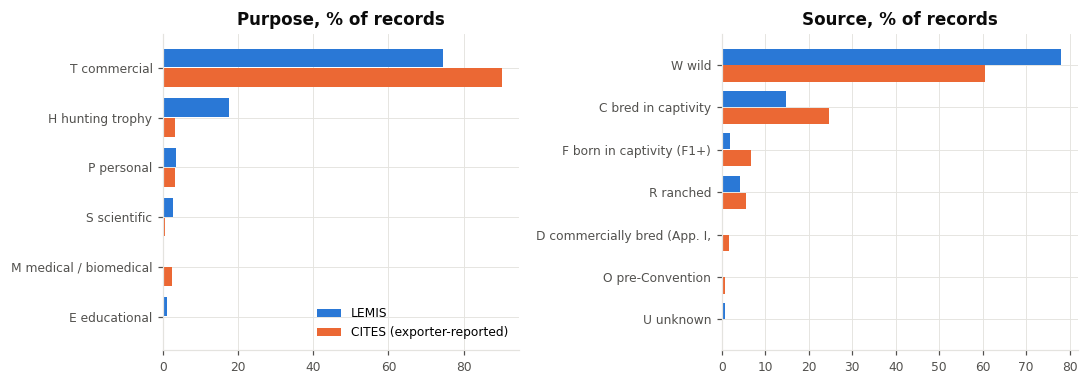

In [17]:
def mix(lcol, ccol, top=None):
    l = Q(f"SELECT {lcol} AS code, count(*) / {N_L} AS lemis FROM lemis GROUP BY 1")
    c = Q(f"SELECT {ccol} AS code, count(*) / {N_E} AS cites FROM win_e GROUP BY 1")
    df = l.merge(c, on="code", how="outer").fillna({"lemis": 0, "cites": 0})
    df["code"] = df.code.fillna("(missing)")
    df = df.assign(m=df[["lemis", "cites"]].max(axis=1)).sort_values("m", ascending=False).drop(columns="m")
    return df.head(top) if top else df

# LEMIS pre-Convention P is shown as CITES's O so the two bars compare like with like
pur = mix("purpose", "Purpose", 6)
src = mix("CASE source WHEN 'P' THEN 'O' ELSE source END", "Source", 7)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
for a, df, title, labels in [(ax[0], pur, "Purpose", E.CITES_PURPOSE),
                             (ax[1], src, "Source", E.CITES_SOURCE)]:
    y = range(len(df))
    a.barh([i - 0.2 for i in y], 100 * df.lemis, height=0.38, color=E.LEMIS_C, label="LEMIS")
    a.barh([i + 0.2 for i in y], 100 * df.cites, height=0.38, color=E.CITES_C, label="CITES (exporter-reported)")
    a.set_yticks(list(y))
    a.set_yticklabels([f"{c} {labels.get(c, '')}"[:28] for c in df.code])
    a.invert_yaxis()
    a.set_title(f"{title}, % of records")
ax[0].legend(loc="lower right")
fig.tight_layout()
pd.concat({"purpose": pur.set_index("code"), "source": src.set_index("code")}).apply(pct)

In [18]:
mix("class", "Class", 12).set_index("code").apply(pct)

,lemis,cites
code,,
Reptilia,13.15%,65.07%
Mammalia,28.84%,8.19%
Anthozoa,12.37%,15.08%
Bivalvia,9.49%,0.11%
(missing),7.32%,0.0%
Actinopterygii,7.1%,0.0%
Aves,6.0%,5.28%
Gastropoda,5.47%,0.28%
Actinopteri,0.0%,4.96%


## 8. Where the two should agree: US imports in the overlap years

LEMIS and the US's own CITES annual report are compiled from the same kind of declarations. For 2013–2014, LEMIS records of CITES-listed taxa (species-level name match, section 5) should resemble CITES records **reported by the US as importer**. Where they differ, the difference is in the encoding rather than in the trade.

In [19]:
con.execute("""CREATE VIEW lemis_listed AS SELECT * FROM lemis
               WHERE species <> 'sp.' AND (genus || ' ' || species) IN (SELECT Taxon FROM cites_taxa)""")
con.execute("""CREATE VIEW cites_us AS SELECT * FROM cites_animals
               WHERE Year IN (2013, 2014) AND Importer = 'US' AND "Reporter.type" = 'I'
                 AND Appendix <> 'N'""")
n_l = Q("SELECT count(*) FROM lemis_listed WHERE year IN (2013, 2014)").iat[0, 0]
n_c = Q("SELECT count(*) FROM cites_us").iat[0, 0]
print(f"LEMIS 2013-14, species-matched to CITES: {n_l:,} line items;  "
      f"CITES 2013-14 reported by the US as importer: {n_c:,} records")


def overlap(lcol, ccol):
    l = Q(f"SELECT {lcol} AS code, count(*) / {n_l} AS lemis FROM lemis_listed WHERE year IN (2013, 2014) GROUP BY 1")
    c = Q(f"SELECT {ccol} AS code, count(*) / {n_c} AS cites_US FROM cites_us GROUP BY 1")
    df = l.merge(c, on="code", how="outer").fillna({"lemis": 0, "cites_US": 0})
    df = df.sort_values("lemis", ascending=False)
    return df.set_index(df.code.fillna("(missing)")).drop(columns="code").head(8).apply(pct)

pd.concat({"purpose": overlap("purpose", "Purpose"),
           "source": overlap("CASE source WHEN 'P' THEN 'O' ELSE source END", "Source")})

LEMIS 2013-14, species-matched to CITES: 243,172 line items;  CITES 2013-14 reported by the US as importer: 246,206 records


lemis cites_US
        code                      
purpose T          78.21%   84.17%
        H          16.29%    10.4%
        P           3.29%    3.27%
        S           0.92%    0.91%
        M            0.9%    0.92%
        Q           0.18%    0.18%
        Z           0.09%    0.08%
        E           0.07%    0.04%
source  W          63.52%   67.21%
        C          20.47%   16.78%
        F          10.09%   11.25%
        R           5.21%    1.31%
        U           0.46%    0.04%
        (missing)   0.15%     0.0%
        O           0.07%    0.51%
        D           0.02%     0.0%

In [20]:
pd.concat({"class": overlap("CASE class WHEN 'Actinopterygii' THEN 'Actinopteri' ELSE class END", "Class")})

lemis cites_US
      code                           
class Reptilia        31.69%   37.27%
      Mammalia        30.48%   14.22%
      Anthozoa        28.76%   44.76%
      Aves             6.56%    1.45%
      Actinopteri      0.71%    0.82%
      Gastropoda       0.49%    0.48%
      Elasmobranchii   0.35%    0.08%
      Bivalvia         0.31%    0.37%

## 9. Fields with no counterpart

| Only in LEMIS | Only in CITES |
|---|---|
| `value` (declared USD), `port`, shipment month, `us_co`, `foreign_co`, `action` / `disposition` (the labels) | `Reporter.type`, permit IDs, `Appendix`, `Order`, `Family`, `Importer` (LEMIS's importer is always the US) |

A model meant to transfer can only use fields both datasets record. LEMIS-only fields can still be used by a LEMIS-only model, as a ceiling on what the shared fields lose.

## Findings and what they imply

| # | Finding | What alignment must do | Report |
|---|---|---|---|
| X1 | **Different units of record.** A LEMIS row is a line item of one US declaration; a CITES row is a permit line item as reported by one of two Parties, so most trade appears twice (notebook 02, C4) | Decide how mirror records are handled before counting, peer-norming or ranking CITES | §3.1, §3.4 |
| X2 | **Different scope.** Matched by name, 28.7% of LEMIS line items are CITES-listed species, 18.9% match only on genus, 1.2% on a higher taxon; 44.3% match nothing and 6.9% have no genus | Choose and state the LEMIS training population (all imports, or CITES-listed taxa); report the match rate and the fallback order (species → genus → higher taxon) | §3.4 |
| X3 | **Source and purpose codes are not identical.** Pre-Convention is `P` in LEMIS (14,291) but `O` in CITES (36,279 exporter-reported); reintroduction is purpose `Y` in LEMIS (402) but `N` in CITES (2,101). CITES source `X` (1,253) has no LEMIS equivalent | An explicit code map (`P`→`O`, `Y`→`N`); unmatched codes → unknown. The claim that the codes are identical is wrong | §3.4 |
| X4 | **Units match one to one** once LEMIS codes are read as words, except CITES `microgrammes` (237) | One unit map with conversion factors to a canonical unit per dimension; never compare across dimensions | §3.4 |
| X5 | **Product vocabularies differ in granularity.** 92 LEMIS codes vs 81 CITES terms, bridged by 31 groups; the current crosswalk leaves <0.05% of rows unmapped, mostly plant products. But the same object is coded differently: LEMIS has separate shoe, garment and trim codes, while CITES records most of these as *leather products (small)*, which is 56% of CITES and 10% of LEMIS | Groups must be defined by how each vocabulary codes the object, not by matching names; check group shares in both datasets after mapping | §3.4 |
| X6 | **Class names** differ: `Actinopterygii` ↔ `Actinopteri`; CITES `Dipneusti` and `Coelacanthi` correspond to LEMIS `Sarcopterygii`. 50+ LEMIS-only classes are unlisted taxa | Class map; LEMIS-only classes can never occur in CITES | §3.4 |
| X7 | **Higher taxa are stored differently**: 64,805 LEMIS rows (137 names, e.g. *Scleractinia* 45,922) have an order/family/class in `genus`, while 86,568 CITES records leave `Genus` blank (*Scleractinia spp.* 60,899) | One convention for both, e.g. take the first word of CITES `Taxon` when `Genus` is blank | §3.4 |
| X8 | **Listings change over time** (pangolins: Appendix II in CITES records to 2016, I from 2017) | An appendix attached to LEMIS should be the one in force in the shipment year, never the latest; exclude Appendix N | §3.4 |
| X9 | **Country codes**: LEMIS `VS` (17,096 values), `ZZ` (2,255), `ZR` (622), `TP` (25) never occur in CITES | Map `VS`→`XV`, `ZZ`→`HS`, `ZR`→`CD`, `TP`→`TL` | §3.4 |
| X10 | **The deployment shift is large.** Commercial purpose 74.5% → 90.4%, hunting trophies 17.6% → 3.0%; wild source 78% → 60%; Reptilia 13% → 65%, Mammalia 29% → 8%, shells 11% → 0.03% | Prefer relative (within-peer-group) features to absolute ones; evaluate on a commercial-only LEMIS subset; measure the shift (domain classifier, PSI) | §3.3, §6.6 |
| X11 | **Where the two should agree, they do.** LEMIS 2013–14 CITES-listed line items (243,172) vs CITES records reported by the US as importer (246,206): near-identical purpose mix (personal 3.29% vs 3.27%) and similar source mix. Differences remain in class (Anthozoa 29% vs 45%) and ranched source (5.2% vs 1.3%) | The code-level alignment is sound; residual differences come from taxon and product reporting granularity, not from the trade | §3.4, §6.6 |
| X12 | `value`, `port`, month and companies exist only in LEMIS; `Reporter.type`, permits, `Appendix`, `Order`, `Family` only in CITES | A transfer model uses only shared fields; LEMIS-only fields serve a LEMIS-only comparison model | §3.4, §4.2 |

### What the shared schema needs (from notebooks 01–03)

Each step cites the findings that require it. These steps are recorded as rules in [`DATA/ALIGNING_LEMIS_AND_CITES.md`](../../DATA/ALIGNING_LEMIS_AND_CITES.md).

1. **Select populations.** LEMIS line items with missing = `NA` or `non-standard value` and exact duplicates kept (L2, L3); the training population still to be chosen and stated (X2, L11). CITES animals with Appendix `N` removed (C2, C5), with a stated rule for mirror records (X1, C4).
2. **Map codes**: source `P`→`O`; purpose `Y`→`N`; anything unmatched or missing → unknown (X3, L3, C12).
3. **Map units** to canonical units per dimension with conversion factors, including `microgrammes`; a blank CITES unit means a count (X4, C9).
4. **Map product form** to shared groups built from how each vocabulary codes an object, at a grain that keeps the high-risk products apart (X5, L9).
5. **Harmonise taxonomy**: class names (`Actinopterygii`→`Actinopteri`, `Sarcopterygii` ↔ `Dipneusti` / `Coelacanthi`) (X6); one higher-taxon convention (X7, L11, C10); for LEMIS, the appendix in force in the shipment year, ignoring `N` (X8, C5).
6. **Map countries**: `VS`→`XV`, `ZZ`→`HS`, `ZR`→`CD`, `TP`→`TL`; a blank CITES origin means the exporter (X9, L12, C11).
7. **Restrict transfer features** to fields both datasets record (X12, L6, L13); log-transform quantities and compare them only within a unit and peer group (L10, C9).
8. **Verify after mapping**: no CITES value of a shared field that is unseen in LEMIS (the test of section 2); product-group shares compared in both datasets (X5); the US overlap comparison repeated (X11).